In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data"
REPORT_DIR = BASE_DIR / "reports"

REPORT_DIR.mkdir(exist_ok=True)

customers_df = pd.read_csv(DATA_DIR / "customers.csv")
merchants_df = pd.read_csv(DATA_DIR / "merchants.csv")
devices_df = pd.read_csv(DATA_DIR / "devices.csv")
transactions_df = pd.read_csv(DATA_DIR / "transactions.csv")
payment_outcomes_df = pd.read_csv(DATA_DIR / "payment_outcomes.csv")
labels_df = pd.read_csv(DATA_DIR / "labels.csv")
features_df = pd.read_csv(DATA_DIR / "features.csv")

In [2]:
print("CUSTOMERS DATASET")
print("Rows and Columns:", customers_df.shape)

display(customers_df.head())
display(customers_df.info())
display(customers_df.describe(include="all").T)

CUSTOMERS DATASET
Rows and Columns: (2500, 6)


,customer_id,created_at,customer_age,home_city,region,is_synthetic
0,C_0004ff2f7739f0d3,2023-04-02T18:30:00+00:00,60,Jaipur,north,True
1,C_00051dee81a46e47,2022-08-01T18:30:00+00:00,39,Lucknow,north,True
2,C_001ba2fd8bb7865d,2023-01-07T18:30:00+00:00,58,Kochi,south,True
3,C_003de39b8bbf9935,2023-01-03T18:30:00+00:00,73,Lucknow,north,True
4,C_004cc14b66cbd9ae,2023-10-26T18:30:00+00:00,67,Jamshedpur,east,True


<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   customer_id   2500 non-null   str  
 1   created_at    2500 non-null   str  
 2   customer_age  2500 non-null   int64
 3   home_city     2500 non-null   str  
 4   region        2500 non-null   str  
 5   is_synthetic  2500 non-null   bool 
dtypes: bool(1), int64(1), str(4)
memory usage: 234.6 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,2500,2500,C_0004ff2f7739f0d3,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,2500,1214,2022-12-07T18:30:00+00:00,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_age,2500.0,NaN,NaN,NaN,49.1112,18.178686,18.0,34.0,49.0,65.0,80.0
home_city,2500,16,Lucknow,177,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2500,6,south,650,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_synthetic,2500,1,True,2500,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
customer_missing = pd.DataFrame({
    "Missing_Count": customers_df.isnull().sum(),
    "Missing_Percentage": (
        customers_df.isnull().mean() * 100
    ).round(2)
})

display(customer_missing)

,Missing_Count,Missing_Percentage
customer_id,0,0.0
created_at,0,0.0
customer_age,0,0.0
home_city,0,0.0
region,0,0.0
is_synthetic,0,0.0


In [4]:
print("Duplicate rows:", customers_df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    customers_df["customer_id"].duplicated().sum()
)

Duplicate rows: 0
Duplicate customer IDs: 0


In [6]:
merchants_df.head()


,merchant_id,synthetic_name,merchant_category,merchant_location,is_synthetic
0,M_00208f2ea071efdc,Synthetic Merchant 000083,travel,"{'lat': 18.52, 'lon': 73.86, 'city': 'Pune'}",True
1,M_00a65588a18e5cb2,Synthetic Merchant 000177,quick_commerce,"{'lat': 19.08, 'lon': 72.88, 'city': 'Mumbai'}",True
2,M_04c9599428747d92,Synthetic Merchant 000062,education,"{'lat': 22.72, 'lon': 75.86, 'city': 'Indore'}",True
3,M_0567943a5de88dab,Synthetic Merchant 000038,healthcare,"{'lat': 22.57, 'lon': 88.36, 'city': 'Kolkata'}",True
4,M_06868839e93b9a80,Synthetic Merchant 000026,gift_cards,"{'lat': 9.93, 'lon': 76.27, 'city': 'Kochi'}",True


In [7]:
merchants_df.shape

(200, 5)

In [9]:
merchants_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   merchant_id        200 non-null    str  
 1   synthetic_name     200 non-null    str  
 2   merchant_category  200 non-null    str  
 3   merchant_location  200 non-null    str  
 4   is_synthetic       200 non-null    bool 
dtypes: bool(1), str(4)
memory usage: 25.7 KB


In [10]:
merchants_df.isnull().sum()

merchant_id          0
synthetic_name       0
merchant_category    0
merchant_location    0
is_synthetic         0
dtype: int64

In [11]:
merchants_df.duplicated().sum()

np.int64(0)

In [13]:
merchants_df.columns

Index(['merchant_id', 'synthetic_name', 'merchant_category',
       'merchant_location', 'is_synthetic'],
      dtype='str')

In [17]:
merchants_df.describe(include="all").T

,count,unique,top,freq
merchant_id,200,200,M_00208f2ea071efdc,1
synthetic_name,200,200,Synthetic Merchant 000083,1
merchant_category,200,10,travel,20
merchant_location,200,16,"{'lat': 18.52, 'lon': 73.86, 'city': 'Pune'}",13
is_synthetic,200,1,True,200


In [18]:
merchants_df["merchant_id"].duplicated().sum()

np.int64(0)

In [19]:
merchants_df["merchant_category"].value_counts(dropna=False)

merchant_category
travel            20
quick_commerce    20
education         20
healthcare        20
gift_cards        20
food              20
gaming            20
other             20
grocery           20
electronics       20
Name: count, dtype: int64

In [20]:
merchants_df.dtypes

merchant_id           str
synthetic_name        str
merchant_category     str
merchant_location     str
is_synthetic         bool
dtype: object

In [22]:
merchants_df["merchant_category"].value_counts(dropna=False,normalize = True)*100

merchant_category
travel            10.0
quick_commerce    10.0
education         10.0
healthcare        10.0
gift_cards        10.0
food              10.0
gaming            10.0
other             10.0
grocery           10.0
electronics       10.0
Name: proportion, dtype: float64

In [23]:
devices_df.head()

,device_id,device_kind,is_synthetic
0,D_000ce3ddcb56a49d,mobile,True
1,D_00135d58adae46a7,mobile,True
2,D_001e2d8c7b1ca90e,mobile,True
3,D_002135db045866c0,mobile,True
4,D_002afc6fb91b9af0,mobile,True


In [24]:
devices_df.shape


(10120, 3)

In [25]:
devices_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10120 entries, 0 to 10119
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   device_id     10120 non-null  str  
 1   device_kind   10120 non-null  str  
 2   is_synthetic  10120 non-null  bool 
dtypes: bool(1), str(2)
memory usage: 407.8 KB


In [26]:
devices_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10120 entries, 0 to 10119
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   device_id     10120 non-null  str  
 1   device_kind   10120 non-null  str  
 2   is_synthetic  10120 non-null  bool 
dtypes: bool(1), str(2)
memory usage: 407.8 KB


In [27]:
devices_df.columns

Index(['device_id', 'device_kind', 'is_synthetic'], dtype='str')

In [28]:
devices_df.describe(include="all").T

,count,unique,top,freq
device_id,10120,10120,D_000ce3ddcb56a49d,1
device_kind,10120,2,mobile,7590
is_synthetic,10120,1,True,10120


In [29]:
devices_df.isnull().sum()

device_id       0
device_kind     0
is_synthetic    0
dtype: int64

In [30]:
devices_df.isnull().mean() * 100

device_id       0.0
device_kind     0.0
is_synthetic    0.0
dtype: float64

In [31]:
devices_df.duplicated().sum()

np.int64(0)

In [32]:
devices_df["device_id"].duplicated().sum()

np.int64(0)

In [34]:
devices_df[devices_df["device_id"].duplicated(keep=False)]

,device_id,device_kind,is_synthetic


In [35]:
devices_df.columns

Index(['device_id', 'device_kind', 'is_synthetic'], dtype='str')

In [37]:
devices_df.dtypes

device_id        str
device_kind      str
is_synthetic    bool
dtype: object

In [38]:
transactions_df.head()

,transaction_id,customer_id,merchant_id,device_id,amount_paise,transaction_amount,payment_channel,merchant_category,transaction_time,customer_age,customer_location,merchant_location,account_age,previous_transactions,average_transaction_value,failed_transactions,split,is_synthetic
0,TX_0000000001,C_b90ff711ce3e3dba,M_11944cb1c387facc,D_e3a0dd890f209d38,79038,790.38,UPI,gift_cards,2024-09-30T18:35:15.602+00:00,52,NaN,"{'lat': 12.97, 'lon': 77.59, 'city': 'Bengaluru'}",836,0,NaN,0,warmup,True
1,TX_0000000002,C_b90ff711ce3e3dba,M_11944cb1c387facc,D_e3a0dd890f209d38,231980,2319.80,UPI,gift_cards,2024-09-30T18:36:10.733+00:00,52,"{'lat': 19.08, 'lon': 72.88, 'city': 'Mumbai'}","{'lat': 12.97, 'lon': 77.59, 'city': 'Bengaluru'}",836,1,790.38,1,warmup,True
2,TX_0000000003,C_b90ff711ce3e3dba,M_11944cb1c387facc,D_e3a0dd890f209d38,113282,1132.82,UPI,gift_cards,2024-09-30T18:37:47.985+00:00,52,"{'lat': 19.08, 'lon': 72.88, 'city': 'Mumbai'}","{'lat': 12.97, 'lon': 77.59, 'city': 'Bengaluru'}",836,2,1555.09,2,warmup,True
3,TX_0000000004,C_b90ff711ce3e3dba,M_11944cb1c387facc,D_e3a0dd890f209d38,32520,325.20,UPI,gift_cards,2024-09-30T18:38:19.318+00:00,52,"{'lat': 19.08, 'lon': 72.88, 'city': 'Mumbai'}","{'lat': 12.97, 'lon': 77.59, 'city': 'Bengaluru'}",836,3,1414.33,2,warmup,True
4,TX_0000000005,C_b90ff711ce3e3dba,M_11944cb1c387facc,D_e3a0dd890f209d38,45515,455.15,UPI,gift_cards,2024-09-30T18:39:15.746+00:00,52,"{'lat': 19.08, 'lon': 72.88, 'city': 'Mumbai'}","{'lat': 12.97, 'lon': 77.59, 'city': 'Bengaluru'}",836,4,1142.05,3,warmup,True


In [39]:
transactions_df.shape

(110000, 18)

In [40]:
transactions_df.columns

Index(['transaction_id', 'customer_id', 'merchant_id', 'device_id',
       'amount_paise', 'transaction_amount', 'payment_channel',
       'merchant_category', 'transaction_time', 'customer_age',
       'customer_location', 'merchant_location', 'account_age',
       'previous_transactions', 'average_transaction_value',
       'failed_transactions', 'split', 'is_synthetic'],
      dtype='str')

In [41]:
transactions_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110000 entries, 0 to 109999
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   transaction_id             110000 non-null  str    
 1   customer_id                110000 non-null  str    
 2   merchant_id                110000 non-null  str    
 3   device_id                  108862 non-null  str    
 4   amount_paise               110000 non-null  int64  
 5   transaction_amount         110000 non-null  float64
 6   payment_channel            110000 non-null  str    
 7   merchant_category          110000 non-null  str    
 8   transaction_time           110000 non-null  str    
 9   customer_age               110000 non-null  int64  
 10  customer_location          106743 non-null  str    
 11  merchant_location          110000 non-null  str    
 12  account_age                110000 non-null  int64  
 13  previous_transactions      110000 non-nu

In [42]:
transactions_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,110000,110000,TX_0000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,110000,2480,C_a4a4d791208c1ba5,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_id,110000,200,M_d87cb6d8eb1f1e96,1130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_id,108862,5405,D_44e48d600c2deea3,128,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_paise,110000.0,NaN,NaN,NaN,447811.527673,9579959.9346,820.0,58255.0,125034.0,271758.5,799593305.0
transaction_amount,110000.0,NaN,NaN,NaN,4478.115277,95799.599346,8.2,582.55,1250.34,2717.585,7995933.05
payment_channel,110000,4,UPI,63927,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_category,110000,10,grocery,20358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_time,110000,110000,2024-09-30T18:35:15.602+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_age,110000.0,NaN,NaN,NaN,48.9934,18.092498,18.0,34.0,49.0,64.0,80.0


In [43]:
transactions_df.isnull().sum()

transaction_id                  0
customer_id                     0
merchant_id                     0
device_id                    1138
amount_paise                    0
transaction_amount              0
payment_channel                 0
merchant_category               0
transaction_time                0
customer_age                    0
customer_location            3257
merchant_location               0
account_age                     0
previous_transactions           0
average_transaction_value    2829
failed_transactions             0
split                           0
is_synthetic                    0
dtype: int64

In [44]:
transactions_df.isnull().mean() * 100

transaction_id               0.000000
customer_id                  0.000000
merchant_id                  0.000000
device_id                    1.034545
amount_paise                 0.000000
transaction_amount           0.000000
payment_channel              0.000000
merchant_category            0.000000
transaction_time             0.000000
customer_age                 0.000000
customer_location            2.960909
merchant_location            0.000000
account_age                  0.000000
previous_transactions        0.000000
average_transaction_value    2.571818
failed_transactions          0.000000
split                        0.000000
is_synthetic                 0.000000
dtype: float64

In [45]:
transactions_df.duplicated().sum()

np.int64(0)

In [46]:
transactions_df["transaction_id"].duplicated().sum()

np.int64(0)

In [47]:
transactions_df[
    transactions_df["transaction_id"].duplicated(keep=False)
].sort_values("transaction_id")

,transaction_id,customer_id,merchant_id,device_id,amount_paise,transaction_amount,payment_channel,merchant_category,transaction_time,customer_age,customer_location,merchant_location,account_age,previous_transactions,average_transaction_value,failed_transactions,split,is_synthetic


In [48]:
transactions_df.dtypes

transaction_id                   str
customer_id                      str
merchant_id                      str
device_id                        str
amount_paise                   int64
transaction_amount           float64
payment_channel                  str
merchant_category                str
transaction_time                 str
customer_age                   int64
customer_location                str
merchant_location                str
account_age                    int64
previous_transactions          int64
average_transaction_value    float64
failed_transactions            int64
split                            str
is_synthetic                    bool
dtype: object

In [49]:
transactions_df["transaction_time"].head()

0    2024-09-30T18:35:15.602+00:00
1    2024-09-30T18:36:10.733+00:00
2    2024-09-30T18:37:47.985+00:00
3    2024-09-30T18:38:19.318+00:00
4    2024-09-30T18:39:15.746+00:00
Name: transaction_time, dtype: str

In [50]:
transactions_df["transaction_time"] = pd.to_datetime(
    transactions_df["transaction_time"],
    errors="coerce",
    utc=True
)

In [51]:
transactions_df["transaction_time"].dtype

datetime64[us, UTC]

In [52]:
transactions_df["transaction_time"].isnull().sum()

np.int64(125)

In [53]:
transactions_df["amount_paise"].describe()

count    1.100000e+05
mean     4.478115e+05
std      9.579960e+06
min      8.200000e+02
25%      5.825500e+04
50%      1.250340e+05
75%      2.717585e+05
max      7.995933e+08
Name: amount_paise, dtype: float64

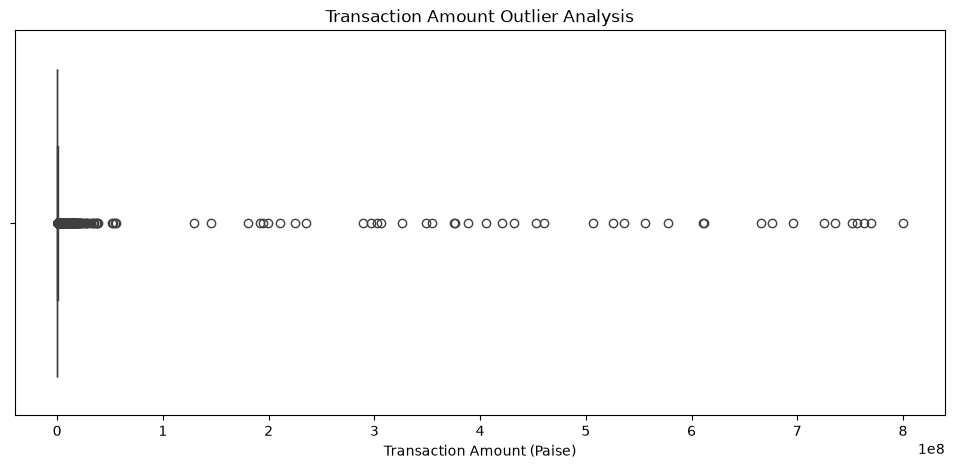

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=transactions_df["amount_paise"]
)

plt.title("Transaction Amount Outlier Analysis")
plt.xlabel("Transaction Amount (Paise)")

plt.show()

In [55]:
payment_outcomes_df.head()

,transaction_id,outcome_time,status,failure_code,is_synthetic
0,TX_0000000001,2024-09-30T18:35:16.622+00:00,FAILED,SIMULATED_AUTH_FAILURE,True
1,TX_0000000002,2024-09-30T18:36:11.876+00:00,FAILED,SIMULATED_AUTH_FAILURE,True
2,TX_0000000003,2024-09-30T18:37:48.053+00:00,SUCCESS,NaN,True
3,TX_0000000004,2024-09-30T18:38:20.578+00:00,FAILED,SIMULATED_AUTH_FAILURE,True
4,TX_0000000005,2024-09-30T18:39:16.087+00:00,FAILED,SIMULATED_AUTH_FAILURE,True


In [56]:
payment_outcomes_df.shape

(110000, 5)

In [57]:
payment_outcomes_df.columns

Index(['transaction_id', 'outcome_time', 'status', 'failure_code',
       'is_synthetic'],
      dtype='str')

In [58]:
payment_outcomes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110000 entries, 0 to 109999
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype
---  ------          --------------   -----
 0   transaction_id  110000 non-null  str  
 1   outcome_time    110000 non-null  str  
 2   status          110000 non-null  str  
 3   failure_code    12015 non-null   str  
 4   is_synthetic    110000 non-null  bool 
dtypes: bool(1), str(4)
memory usage: 8.8 MB


In [59]:
payment_outcomes_df.describe(include="all").T

,count,unique,top,freq
transaction_id,110000,110000,TX_0000000001,1
outcome_time,110000,109999,2024-10-15T20:35:37.132+00:00,2
status,110000,2,SUCCESS,97985
failure_code,12015,1,SIMULATED_AUTH_FAILURE,12015
is_synthetic,110000,1,True,110000


In [60]:
payment_outcomes_df.isnull().sum()

transaction_id        0
outcome_time          0
status                0
failure_code      97985
is_synthetic          0
dtype: int64

In [61]:
payment_outcomes_df.isnull().mean() * 100

transaction_id     0.000000
outcome_time       0.000000
status             0.000000
failure_code      89.077273
is_synthetic       0.000000
dtype: float64

In [62]:
payment_outcomes_df.duplicated().sum()

np.int64(0)

In [63]:
payment_outcomes_df["transaction_id"].duplicated().sum()

np.int64(0)

In [64]:
payment_outcomes_df[
    payment_outcomes_df["transaction_id"].duplicated(keep=False)
].sort_values("transaction_id")

,transaction_id,outcome_time,status,failure_code,is_synthetic


In [65]:
payment_outcomes_df.dtypes

transaction_id     str
outcome_time       str
status             str
failure_code       str
is_synthetic      bool
dtype: object

In [66]:
payment_outcomes_df["outcome_time"].head()

0    2024-09-30T18:35:16.622+00:00
1    2024-09-30T18:36:11.876+00:00
2    2024-09-30T18:37:48.053+00:00
3    2024-09-30T18:38:20.578+00:00
4    2024-09-30T18:39:16.087+00:00
Name: outcome_time, dtype: str

In [67]:
payment_outcomes_df["outcome_time"] = pd.to_datetime(
    payment_outcomes_df["outcome_time"],
    errors="coerce",
    utc=True
)

In [68]:
payment_outcomes_df["outcome_time"].isnull().sum()

np.int64(91)

In [69]:
payment_outcomes_df["status"].value_counts(dropna=False)

status
SUCCESS    97985
FAILED     12015
Name: count, dtype: int64

In [70]:
payment_outcomes_df["status"].value_counts(
    normalize=True,
    dropna=False
) * 100

status
SUCCESS    89.077273
FAILED     10.922727
Name: proportion, dtype: float64

In [71]:
payment_outcomes_df["failure_code"].value_counts(
    dropna=False
)

failure_code
NaN                       97985
SIMULATED_AUTH_FAILURE    12015
Name: count, dtype: int64

In [72]:
labels_df.head()

,transaction_id,fraud_label,label_source,label_available_at,split,eligible_at_next_split_start,is_synthetic
0,TX_0000000001,0,mature_no_fraud,2024-11-29T18:35:15.602+00:00,warmup,True,True
1,TX_0000000002,0,mature_no_fraud,2024-11-29T18:36:10.733+00:00,warmup,True,True
2,TX_0000000003,0,mature_no_fraud,2024-11-29T18:37:47.985+00:00,warmup,True,True
3,TX_0000000004,0,mature_no_fraud,2024-11-29T18:38:19.318+00:00,warmup,True,True
4,TX_0000000005,0,mature_no_fraud,2024-11-29T18:39:15.746+00:00,warmup,True,True


In [75]:
labels_df.shape

(110000, 7)

In [74]:
labels_df.columns

Index(['transaction_id', 'fraud_label', 'label_source', 'label_available_at',
       'split', 'eligible_at_next_split_start', 'is_synthetic'],
      dtype='str')

In [76]:
labels_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110000 entries, 0 to 109999
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   transaction_id                110000 non-null  str  
 1   fraud_label                   110000 non-null  int64
 2   label_source                  110000 non-null  str  
 3   label_available_at            110000 non-null  str  
 4   split                         110000 non-null  str  
 5   eligible_at_next_split_start  110000 non-null  bool 
 6   is_synthetic                  110000 non-null  bool 
dtypes: bool(2), int64(1), str(4)
memory usage: 11.0 MB


In [77]:
labels_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,110000,110000,TX_0000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fraud_label,110000.0,NaN,NaN,NaN,0.006,0.077227,0.0,0.0,0.0,0.0,1.0
label_source,110000,3,mature_no_fraud,109340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
label_available_at,110000,110000,2024-11-29T18:35:15.602+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,110000,4,train,72050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eligible_at_next_split_start,110000,2,True,81908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_synthetic,110000,1,True,110000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [78]:
labels_df.isnull().sum()

transaction_id                  0
fraud_label                     0
label_source                    0
label_available_at              0
split                           0
eligible_at_next_split_start    0
is_synthetic                    0
dtype: int64

In [79]:
labels_df.isnull().mean() * 100

transaction_id                  0.0
fraud_label                     0.0
label_source                    0.0
label_available_at              0.0
split                           0.0
eligible_at_next_split_start    0.0
is_synthetic                    0.0
dtype: float64

In [80]:
labels_df.duplicated().sum()

np.int64(0)

In [81]:
labels_df["transaction_id"].duplicated().sum()

np.int64(0)

In [82]:
labels_df[
    labels_df["transaction_id"].duplicated(keep=False)
].sort_values("transaction_id")

,transaction_id,fraud_label,label_source,label_available_at,split,eligible_at_next_split_start,is_synthetic


In [83]:
labels_df.dtypes

transaction_id                    str
fraud_label                     int64
label_source                      str
label_available_at                str
split                             str
eligible_at_next_split_start     bool
is_synthetic                     bool
dtype: object

In [84]:
labels_df["label_available_at"].head()

0    2024-11-29T18:35:15.602+00:00
1    2024-11-29T18:36:10.733+00:00
2    2024-11-29T18:37:47.985+00:00
3    2024-11-29T18:38:19.318+00:00
4    2024-11-29T18:39:15.746+00:00
Name: label_available_at, dtype: str

In [85]:
labels_df["label_available_at"] = pd.to_datetime(
    labels_df["label_available_at"],
    errors="coerce",
    utc=True
)

In [86]:
labels_df["label_available_at"].isnull().sum()

np.int64(125)

In [87]:
labels_df["fraud_label"].value_counts(dropna=False)

fraud_label
0    109340
1       660
Name: count, dtype: int64

In [88]:
labels_df["fraud_label"].value_counts(
    normalize=True,
    dropna=False
) * 100

fraud_label
0    99.4
1     0.6
Name: proportion, dtype: float64

In [89]:
labels_df["split"].value_counts(dropna=False)

split
train         72050
validation    14061
holdout       13889
warmup        10000
Name: count, dtype: int64

In [90]:
pd.crosstab(
    labels_df["split"],
    labels_df["fraud_label"],
    margins=True
)

fraud_label,0,1,All
split,,,
holdout,13816,73,13889
train,71612,438,72050
validation,13972,89,14061
warmup,9940,60,10000
All,109340,660,110000


In [91]:
features_df.head()

,transaction_id,feature_as_of,amount_to_avg_ratio,is_new_device,customer_merchant_distance_km,is_new_city,hour_of_day,is_night,has_recent_failures,is_new_account,...,distinct_customers_per_device_7d,combined_risk_flags,mcc_target_encoded_rate,mcc_encoding_as_of,mcc_encoding_count,missing_customer_location,missing_device,cold_start,reason_codes,feature_version
0,TX_0000000001,2024-09-30T18:35:15.602+00:00,NaN,True,NaN,NaN,0,True,False,False,...,0.0,2,0.006,2024-09-30T18:30:00+00:00,0,True,False,True,"['R01_NEW_DEVICE', 'R03_ODD_HOUR', 'R08_HIGH_R...",sentinel-features-1.0.0
1,TX_0000000002,2024-09-30T18:36:10.733+00:00,2.9350,False,845.38,True,0,True,False,False,...,1.0,2,0.006,2024-09-30T18:30:00+00:00,0,False,False,False,"['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...",sentinel-features-1.0.0
2,TX_0000000003,2024-09-30T18:37:47.985+00:00,0.7285,False,845.38,False,0,True,False,False,...,1.0,2,0.006,2024-09-30T18:30:00+00:00,0,False,False,False,"['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...",sentinel-features-1.0.0
3,TX_0000000004,2024-09-30T18:38:19.318+00:00,0.2299,False,845.38,False,0,True,False,False,...,1.0,2,0.006,2024-09-30T18:30:00+00:00,0,False,False,False,"['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...",sentinel-features-1.0.0
4,TX_0000000005,2024-09-30T18:39:15.746+00:00,0.3985,False,845.38,False,0,True,True,False,...,1.0,3,0.006,2024-09-30T18:30:00+00:00,0,False,False,False,"['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R04_FAIL...",sentinel-features-1.0.0


In [92]:
features_df.shape

(110000, 22)

In [93]:
features_df.columns

Index(['transaction_id', 'feature_as_of', 'amount_to_avg_ratio',
       'is_new_device', 'customer_merchant_distance_km', 'is_new_city',
       'hour_of_day', 'is_night', 'has_recent_failures', 'is_new_account',
       'txn_count_last_1h', 'txn_amount_last_24h_paise',
       'distinct_customers_per_device_7d', 'combined_risk_flags',
       'mcc_target_encoded_rate', 'mcc_encoding_as_of', 'mcc_encoding_count',
       'missing_customer_location', 'missing_device', 'cold_start',
       'reason_codes', 'feature_version'],
      dtype='str')

In [94]:
features_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110000 entries, 0 to 109999
Data columns (total 22 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   transaction_id                    110000 non-null  str    
 1   feature_as_of                     110000 non-null  str    
 2   amount_to_avg_ratio               107171 non-null  float64
 3   is_new_device                     108862 non-null  object 
 4   customer_merchant_distance_km     106743 non-null  float64
 5   is_new_city                       106743 non-null  object 
 6   hour_of_day                       110000 non-null  int64  
 7   is_night                          110000 non-null  bool   
 8   has_recent_failures               110000 non-null  bool   
 9   is_new_account                    110000 non-null  bool   
 10  txn_count_last_1h                 110000 non-null  int64  
 11  txn_amount_last_24h_paise         110000 non-null  int64  
 12 

In [95]:
features_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,110000,110000,TX_0000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feature_as_of,110000,110000,2024-09-30T18:35:15.602+00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount_to_avg_ratio,107171.0,NaN,NaN,NaN,2.771739,123.156839,0.0001,0.4127,0.7467,1.35555,30211.6359
is_new_device,108862,2,False,101557,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_merchant_distance_km,106743.0,NaN,NaN,NaN,1046.27526,554.756284,0.0,594.53,1080.74,1443.1,2428.81
is_new_city,106743,2,False,98978,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hour_of_day,110000.0,NaN,NaN,NaN,12.746018,6.503543,0.0,8.0,13.0,18.0,23.0
is_night,110000,2,False,94562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
has_recent_failures,110000,2,False,100123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_new_account,110000,2,False,108891,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [96]:
features_df.isnull().sum()

transaction_id                         0
feature_as_of                          0
amount_to_avg_ratio                 2829
is_new_device                       1138
customer_merchant_distance_km       3257
is_new_city                         3257
hour_of_day                            0
is_night                               0
has_recent_failures                    0
is_new_account                         0
txn_count_last_1h                      0
txn_amount_last_24h_paise              0
distinct_customers_per_device_7d    1138
combined_risk_flags                    0
mcc_target_encoded_rate                0
mcc_encoding_as_of                     0
mcc_encoding_count                     0
missing_customer_location              0
missing_device                         0
cold_start                             0
reason_codes                           0
feature_version                        0
dtype: int64

In [97]:
features_df.isnull().mean() * 100

transaction_id                      0.000000
feature_as_of                       0.000000
amount_to_avg_ratio                 2.571818
is_new_device                       1.034545
customer_merchant_distance_km       2.960909
is_new_city                         2.960909
hour_of_day                         0.000000
is_night                            0.000000
has_recent_failures                 0.000000
is_new_account                      0.000000
txn_count_last_1h                   0.000000
txn_amount_last_24h_paise           0.000000
distinct_customers_per_device_7d    1.034545
combined_risk_flags                 0.000000
mcc_target_encoded_rate             0.000000
mcc_encoding_as_of                  0.000000
mcc_encoding_count                  0.000000
missing_customer_location           0.000000
missing_device                      0.000000
cold_start                          0.000000
reason_codes                        0.000000
feature_version                     0.000000
dtype: flo

In [98]:
features_df.duplicated().sum()

np.int64(0)

In [99]:
features_df["transaction_id"].duplicated().sum()

np.int64(0)

In [100]:
features_df.dtypes

transaction_id                          str
feature_as_of                           str
amount_to_avg_ratio                 float64
is_new_device                        object
customer_merchant_distance_km       float64
is_new_city                          object
hour_of_day                           int64
is_night                               bool
has_recent_failures                    bool
is_new_account                         bool
txn_count_last_1h                     int64
txn_amount_last_24h_paise             int64
distinct_customers_per_device_7d    float64
combined_risk_flags                   int64
mcc_target_encoded_rate             float64
mcc_encoding_as_of                      str
mcc_encoding_count                    int64
missing_customer_location              bool
missing_device                         bool
cold_start                             bool
reason_codes                            str
feature_version                         str
dtype: object

In [101]:
features_df.describe().T

,count,mean,std,min,25%,50%,75%,max
amount_to_avg_ratio,107171.0,2.771739,1.231568e+02,0.000100,0.412700,0.746700,1.35555,3.021164e+04
customer_merchant_distance_km,106743.0,1046.275260,5.547563e+02,0.000000,594.530000,1080.740000,1443.10000,2.428810e+03
hour_of_day,110000.0,12.746018,6.503543e+00,0.000000,8.000000,13.000000,18.00000,2.300000e+01
txn_count_last_1h,110000.0,1.158555,1.861307e+00,0.000000,0.000000,0.000000,1.00000,1.000000e+01
txn_amount_last_24h_paise,110000.0,517726.713618,1.115406e+07,0.000000,0.000000,0.000000,252497.25000,8.007534e+08
distinct_customers_per_device_7d,108862.0,0.592787,5.049452e-01,0.000000,0.000000,1.000000,1.00000,3.000000e+00
combined_risk_flags,110000.0,1.127473,7.286046e-01,0.000000,1.000000,1.000000,1.00000,4.000000e+00
mcc_target_encoded_rate,110000.0,0.006024,7.826173e-03,0.000056,0.000174,0.001269,0.00600,2.580214e-02
mcc_encoding_count,110000.0,3355.430300,3.250959e+03,0.000000,0.000000,2752.000000,5614.00000,1.065700e+04


In [102]:
features_df["is_new_device"].value_counts(dropna=False)

is_new_device
False    101557
True       7305
NaN        1138
Name: count, dtype: int64

In [103]:
features_df["is_night"].value_counts(dropna=False)

is_night
False    94562
True     15438
Name: count, dtype: int64

In [104]:
features_df["is_new_account"].value_counts(dropna=False)

is_new_account
False    108891
True       1109
Name: count, dtype: int64

In [105]:
features_df["reason_codes"].head(10)

0    ['R01_NEW_DEVICE', 'R03_ODD_HOUR', 'R08_HIGH_R...
1    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...
2    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...
3    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...
4    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R04_FAIL...
5    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R04_FAIL...
6    ['R01_NEW_DEVICE', 'R02_GEO_MISMATCH', 'R03_OD...
7    ['R01_NEW_DEVICE', 'R02_GEO_MISMATCH', 'R03_OD...
8    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...
9    ['R02_GEO_MISMATCH', 'R03_ODD_HOUR', 'R08_HIGH...
Name: reason_codes, dtype: str